<h1> Temporal Difference Learning (TD)

Core Idea

TD is a model-free method. This means—unlike Monte Carlo—we do not have:

$P(s'|s,a)$

and we rely solely on experience.

Temporal Difference: A combination of two ideas—DP and Monte Carlo:

$Experience + Bootstrapping -> Value Update$

The concept of **bootstrapping**: using our current estimate to estimate the future.

TD(0) Update Rule Formula

$V(S)
\leftarrow
V(S)
+
\alpha
[
R+\gamma V(S')-V(S)
]$

In [41]:
import numpy as np
import matplotlib.pyplot as plt

from collections import defaultdict

from src.td_prediction import (
    RandomWalk,
    
)

<h3> Step 1: Building the "Random Walk" Environment

In [42]:
states = np.arange(5)

left_terminal = 0
right_terminal = 4

V = np.zeros(
    len(states)
)

V[1:4] = 0.5

In [43]:
states

array([0, 1, 2, 3, 4])

In [44]:
V

array([0. , 0.5, 0.5, 0.5, 0. ])

Why are the intermediate states set to 0.5? Because, prior to learning, we have no information.
In a random walk:
- Reaching the left → Failure
- Reaching the right → Success

So, we assign a neutral initial value:

$0.5$

This means we initially assume a 50% probability of success.

Why are terminal states zero?
Because the value is no longer meaningful for terminal states.
The episode has ended.

Now we need to construct the Random Walk environment, because TD requires observing actual transitions.

In [45]:
env = RandomWalk()
state = env.reset()

print(state)
print(
    env.step("right")
)

2
(3, 0, False)


In a random walk, there are only two possible moves: left and right.

<h3> Step 2: Select Action

In [46]:
def choose_action():
    if np.random.rand() < 0.5:
        return "left"
    return "right"

<h3> Step 3: Episode Generation

In [47]:
def generate_episode(env):
    state = env.reset()
    episode = []

    while True:
        action = choose_action()
        next_state, reward, done = env.step(
            action
        )

        episode.append(
            (
                state,
                reward,
                next_state
            )
        )

        state = next_state

        if done:
            break

    return episode

<h3> Step 4: TD(0) Update

In [48]:
def td_zero(
    env,
    V,
    episodes,
    alpha=0.1,
    gamma=1.0
):
    history = []
    
    for _ in range(episodes):
        episode = generate_episode(env)

        for state, reward, next_state in episode:
            td_target = (
                reward
                +
                gamma * V[next_state]
            )

            td_error = (
                td_target
                -
                V[state]
            )

            V[state] += (
                alpha *
                td_error
            )
 
        history.append(V.copy())

    return V, history

In [49]:
V_td = np.zeros(5)
V_td[1:4] = 0.5

V_td, history = td_zero(
    env,
    V_td,
    episodes=100
)

print(V_td)

[0.         0.21448713 0.54937757 0.76984022 0.        ]


<h3> Step 5: Analyzing Convergence in TD(0)

So far, we have only had a brief training run:
episodes = 100

Now, we want to see whether the value function approaches the true value if we provide more experience.

In [50]:
true_values = np.array(
    [
        0,
        0.25,
        0.5,
        0.75,
        0
    ]
)

In [51]:
V_td = np.zeros(5)
V_td[1:4] = 0.5

V_td, history = td_zero(
    env,
    V_td,
    episodes=10000,
    alpha=0.1,
    gamma=1.0
)

In [52]:
print(
    "Estimated:"
)

print(
    V_td
)


print(
    "True:"
)

print(
    true_values
)

Estimated:
[0.         0.12361987 0.28583912 0.53676813 0.        ]
True:
[0.   0.25 0.5  0.75 0.  ]


<h3> Step 6: Error Calculation (RMSE)

$RMSE=
\sqrt{
\frac{1}{n}
\sum(V_{estimated}-V_{true})^2
}$

In [53]:
def calculate_rmse(V, true_values):
    return np.sqrt(
        np.mean(
            (V[1:4] - true_values[1:4])**2
        )
    )

rmse = calculate_rmse(V_td, true_values)
print(rmse)

0.189124871879118


<h3> Step 7: Recording the learning process

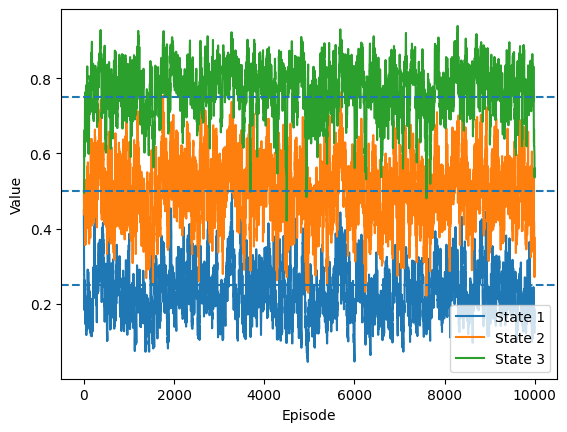

In [54]:
history = np.array(history)

plt.plot(history[:,1], label="State 1")
plt.plot(history[:,2], label="State 2")
plt.plot(history[:,3], label="State 3")

plt.axhline(
    0.25,
    linestyle="--"
)

plt.axhline(
    0.5,
    linestyle="--"
)

plt.axhline(
    0.75,
    linestyle="--"
)

plt.legend()
plt.xlabel("Episode")
plt.ylabel("Value")

plt.show()

Why aren't the lines straight?
Because TD is an online method. Each episode generates a new random path.

<h3> Step 8: TD(0) vs Monte Carlo Prediction

The goal of this comparison is to understand exactly why TD Learning was developed.

Both methods:
- Are model-free.
- Use experience.
- Estimate a value function.

However, the learning method differs.

#### Overview of the Main Difference

1. Monte Carlo
Waits for the episode to end:

$State -> Actions -> Terminal -> Calculate Return -> Update Value$

Meaning:
It sees the complete future reality.


2. TD(0)
Updates immediately:

$State -> Next State -> Estimate Update$

Meaning:
It uses its current estimate to predict the future.

In [55]:
true_values = np.array(
    [
        0.25,
        0.5,
        0.75
    ]
)

In [56]:
def td_zero_with_rmse(
    env,
    V,
    episodes,
    true_values,
    alpha=0.1,
    gamma=1.0
):

    rmse_history = []

    for _ in range(episodes):

        episode = generate_episode(env)


        for state, reward, next_state in episode:

            td_target = (
                reward
                +
                gamma * V[next_state]
            )

            td_error = (
                td_target
                -
                V[state]
            )

            V[state] += (
                alpha * td_error
            )

        rmse = np.sqrt(
            np.mean(
                (
                    V[1:4]
                    -
                    true_values
                )**2
            )
        )

        rmse_history.append(
            rmse
        )


    return V, rmse_history

In [57]:
def mc_prediction_with_rmse(
    env,
    episodes,
    true_values,
    gamma=1.0
):

    returns_sum = defaultdict(float)
    returns_count = defaultdict(float)

    V = np.zeros(5)

    rmse_history = []


    for _ in range(episodes):

        episode = generate_episode(env)

        G = 0

        for state, reward, _ in reversed(episode):
            G = gamma * G + reward
            returns_sum[state] += G
            returns_count[state] += 1

            V[state] = (
                returns_sum[state]
                /
                returns_count[state]
            )

        rmse = np.sqrt(
            np.mean(
                (
                    V[1:4]
                    -
                    true_values
                )**2
            )
        )

        rmse_history.append(
            rmse
        )

    return V, rmse_history

In [58]:
runs = 100
episodes = 1000

In [59]:
V_td, td_rmse_history = td_zero_with_rmse(
    env,
    np.array([0,0.5,0.5,0.5,0]),
    episodes,
    true_values
)

In [60]:
V_mc, mc_rmse_history = mc_prediction_with_rmse(
    env,
    episodes,
    true_values
)

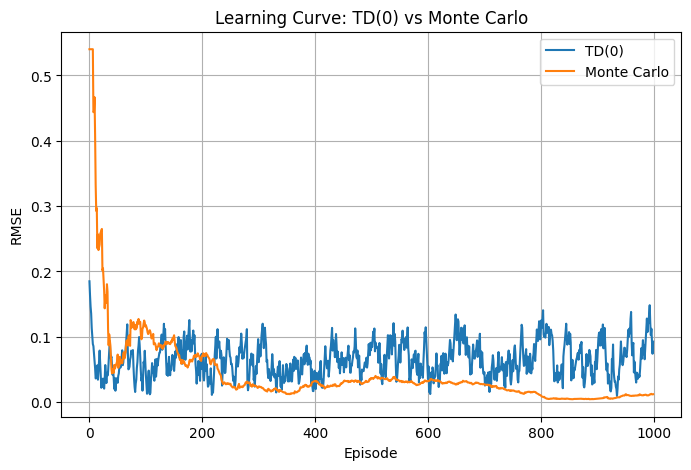

In [61]:
plt.figure(
    figsize=(8,5)
)

plt.plot(
    td_rmse_history,
    label="TD(0)"
)

plt.plot(
    mc_rmse_history,
    label="Monte Carlo"
)

plt.xlabel(
    "Episode"
)

plt.ylabel(
    "RMSE"
)

plt.title(
    "Learning Curve: TD(0) vs Monte Carlo"
)

plt.legend()
plt.grid()
plt.show()

| Method | Initial Speed ​​| Fluctuation | Bias | Variance |
| :--- | :--- | :--- | :--- | :--- |
| TD(0) | Faster | Higher | Higher | Lower |
| Monte Carlo | Slower | Lower | Lower | Higher |

### TD(0) vs Monte Carlo Prediction

The learning curves compare TD(0) and Monte Carlo prediction using RMSE over training episodes.

TD(0) learns faster in the early stages because it updates the value function after every transition using bootstrapping.

However, TD(0) shows higher variance because each update depends on the current value estimates.

Monte Carlo starts slower because it requires complete episodes before updating values, but it becomes more stable as more returns are collected.

The experiment demonstrates the classic trade-off:

- TD methods provide faster learning with more bias.
- Monte Carlo methods provide lower bias but higher variance.